In [52]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [53]:
%%R
lib_loc <- "lib_loc"

Cargamos librerias

In [54]:
%%R
options(repos = c(CRAN = "https://cloud.r-project.org"))

if (!require("psych", lib.loc = lib_loc)) install.packages("psych", lib = lib_loc)
library(psych, lib.loc = lib_loc)
if (!require("plyr", lib.loc = lib_loc)) install.packages("plyr", lib = lib_loc)
library(plyr, lib.loc = lib_loc)
if (!require("Rmisc", lib.loc = lib_loc)) install.packages("Rmisc", lib = lib_loc)
library(Rmisc, lib.loc = lib_loc)

# Carga del fichero

In [55]:
%%R

dfMedidas <- read.csv("SeoulBikeData.csv", 
                      sep = ",", dec = ".", 
                      check.names = FALSE, 
                      stringsAsFactors = TRUE, 
                      header = TRUE, 
                      fill = TRUE)


Visualizamos los datos

In [56]:
%%R
head(dfMedidas, 5)

        Date Rented_Bike_Count Hour Temperature Humidity Wind_speed Visibility
1 01/12/2017               254    0        -5.2       37        2.2       2000
2 01/12/2017               204    1        -5.5       38        0.8       2000
3 01/12/2017               173    2        -6.0       39        1.0       2000
4 01/12/2017               107    3        -6.2       40        0.9       2000
5 01/12/2017                78    4        -6.0       36        2.3       2000
  Dew_point_temperature Solar_Radiation Rainfall Snowfall Seasons    Holiday
1                 -17.6               0        0        0  Winter No Holiday
2                 -17.6               0        0        0  Winter No Holiday
3                 -17.7               0        0        0  Winter No Holiday
4                 -17.6               0        0        0  Winter No Holiday
5                 -18.6               0        0        0  Winter No Holiday
  Functioning Day
1             Yes
2             Yes
3         

Analizamos los tipos de variables

In [57]:
%%R
str(dfMedidas)

'data.frame':	8760 obs. of  14 variables:
 $ Date                 : Factor w/ 365 levels "01/01/2018","01/02/2018",..: 12 12 12 12 12 12 12 12 12 12 ...
 $ Rented_Bike_Count    : int  254 204 173 107 78 100 181 460 930 490 ...
 $ Hour                 : int  0 1 2 3 4 5 6 7 8 9 ...
 $ Temperature          : num  -5.2 -5.5 -6 -6.2 -6 -6.4 -6.6 -7.4 -7.6 -6.5 ...
 $ Humidity             : int  37 38 39 40 36 37 35 38 37 27 ...
 $ Wind_speed           : num  2.2 0.8 1 0.9 2.3 1.5 1.3 0.9 1.1 0.5 ...
 $ Visibility           : int  2000 2000 2000 2000 2000 2000 2000 2000 2000 1928 ...
 $ Dew_point_temperature: num  -17.6 -17.6 -17.7 -17.6 -18.6 -18.7 -19.5 -19.3 -19.8 -22.4 ...
 $ Solar_Radiation      : num  0 0 0 0 0 0 0 0 0.01 0.23 ...
 $ Rainfall             : num  0 0 0 0 0 0 0 0 0 0 ...
 $ Snowfall             : num  0 0 0 0 0 0 0 0 0 0 ...
 $ Seasons              : Factor w/ 4 levels "Autumn","Spring",..: 4 4 4 4 4 4 4 4 4 4 ...
 $ Holiday              : Factor w/ 2 levels "Holiday","N

# EDA

Como podemos observar hay un total de 8760 instancias con 14 variables.
Estas variables se pueden dividir en categóricas y numéricas:

1)   Categóricas:
  * Seasons: Estación del año
  * Date: Fecha
  * Holiday: Periodo de vacaciones, binario
  * Functioning Day: Día laboral, binaria

2)   Numéricas:
  * Rented Bike Count (Variable objetivo): Número de bicicletas alquiladas por cada hora
  * Temperature: Temperatura
  * Humidity: Humedad
  * Wind Speed: Velocidad del viento
  * Visibility: Visibilidad medida en decenas de metros
  * Dew Point Temperature: Temperatura del punto de rocío
  * Solar Radiation: Radiación solar medido en MJ/m2
  * Rainfall: mm de lluvia
  * Snowfall: cm de nieve
  * Hour: Hora


  Hay que destacar que los valores de las variables categóricas Holiday y Functioning Day son binarios, por lo que más adelante se cambiarán a 1s y 0s.

Para conocer los datos con más detalle hay que evaluar los siguientes conceptos:


*   Columnas faltantes o irrelevantes
*   Variables categóricas con mayor cardinalidad
*   Variables con valores faltantes
*   Correlación de las variables numéricas

In [58]:
%%R
describe(dfMedidas)

                      vars    n    mean     sd  median trimmed    mad   min
Date*                    1 8760  183.00 105.37  183.00  183.00 134.92   1.0
Rented_Bike_Count        2 8760  704.60 645.00  504.50  612.58 553.75   0.0
Hour                     3 8760   11.50   6.92   11.50   11.50   8.90   0.0
Temperature              4 8760   12.88  11.94   13.70   13.19  13.94 -17.8
Humidity                 5 8760   58.23  20.36   57.00   58.02  23.72   0.0
Wind_speed               6 8760    1.72   1.04    1.50    1.63   1.04   0.0
Visibility               7 8760 1436.83 608.30 1698.00 1509.50 447.75  27.0
Dew_point_temperature    8 8760    4.07  13.06    5.10    4.76  14.38 -30.6
Solar_Radiation          9 8760    0.57   0.87    0.01    0.38   0.01   0.0
Rainfall                10 8760    0.15   1.13    0.00    0.00   0.00   0.0
Snowfall                11 8760    0.08   0.44    0.00    0.00   0.00   0.0
Seasons*                12 8760    2.50   1.11    2.00    2.49   1.48   1.0
Holiday*    

Como podemos ver que no hay valores faltantes ni constantes, la cardinalidad máxima dentro de las variables categóricas es de 4, sin embargo, una columna que podemos considerar irrelevante es la fecha, pues tampoco aporta más información que el momento del año en que se ha tomado, información que se puede obtener también de la variable Seasons.
Sin embargo, esperaremos a ver cuanto de correlada está con la variable objetivo para decidir su eliminación.

Evaluamos también la presencia de outlier con los diagramas de caja.

%%R
boxplot(dfMedidas$WindSpeed, main = "Boxplot of WindSpeed", xlab = "WindSpeed", ylab = "WindSpeed")
boxplot(dfMedidas$DewPointTemperature, main = "Boxplot of DewPointTemperature", xlab = "DewPointTemperature", ylab = "DewPointTemperature")
boxplot(dfMedidas$SolarRadiation, main = "Boxplot of SolarRadiation", xlab = "SolarRadiation", ylab = "SolarRadiation")

In [68]:
%%R
table(dfMedidas$Solar_Radiation)


   0 0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09  0.1 0.11 0.12 0.13 0.14 0.15 
4300  128   82   69   47   54   61   37   33   32   36   44   32   33   33   24 
0.16 0.17 0.18 0.19  0.2 0.21 0.22 0.23 0.24 0.25 0.26 0.27 0.28 0.29  0.3 0.31 
  36   27   32   30   28   31   25   31   16   28   24   20   24   22   17   22 
0.32 0.33 0.34 0.35 0.36 0.37 0.38 0.39  0.4 0.41 0.42 0.43 0.44 0.45 0.46 0.47 
  27   14   36   20   26   17   19   22   21   25   24   23   17   25   14   26 
0.48 0.49  0.5 0.51 0.52 0.53 0.54 0.55 0.56 0.57 0.58 0.59  0.6 0.61 0.62 0.63 
  20   20   18   19   29   19   25   22   21   25   18   17   19   14   17   15 
0.64 0.65 0.66 0.67 0.68 0.69  0.7 0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 
  17   16   12    9   16   14   11    6   17   10   14   14   19   15   15   15 
 0.8 0.81 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89  0.9 0.91 0.92 0.93 0.94 0.95 
  16   19   12   12   18   12   14   20   18   17   13   19   14   22   20   13 
0.96 0.97 0.98 0.99    1 1.

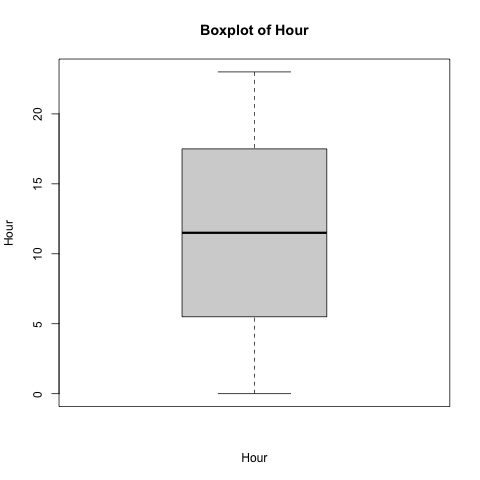

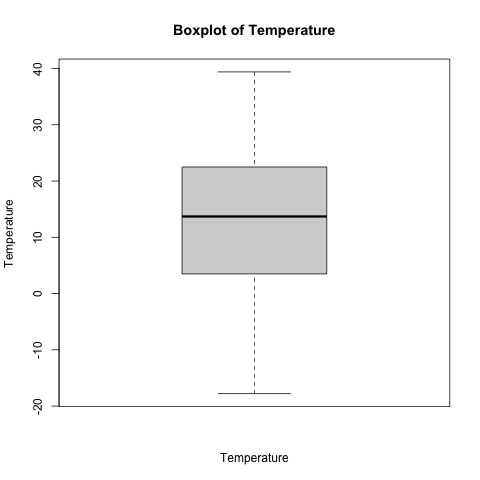

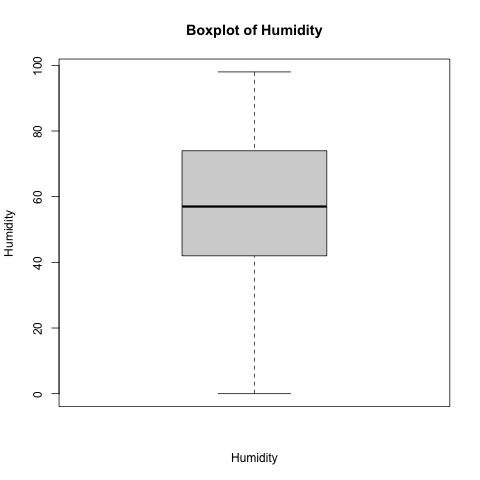

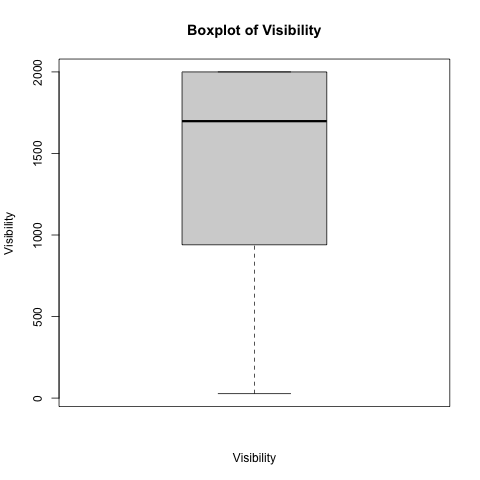

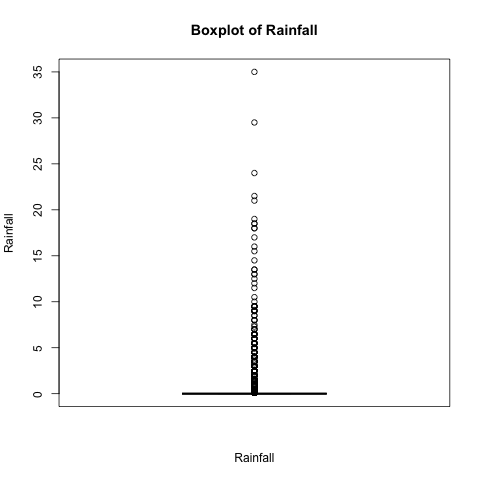

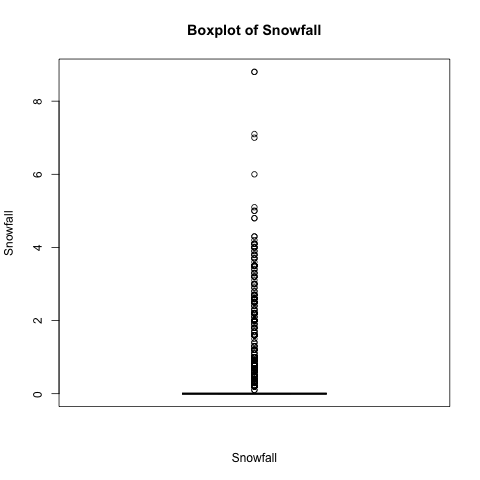

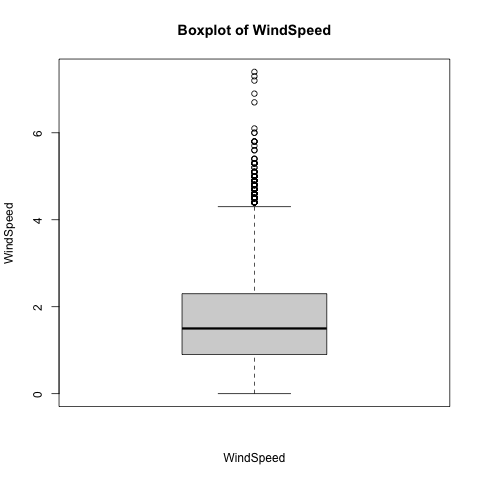

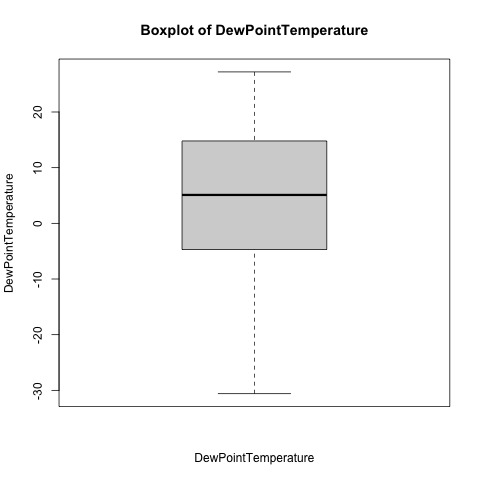

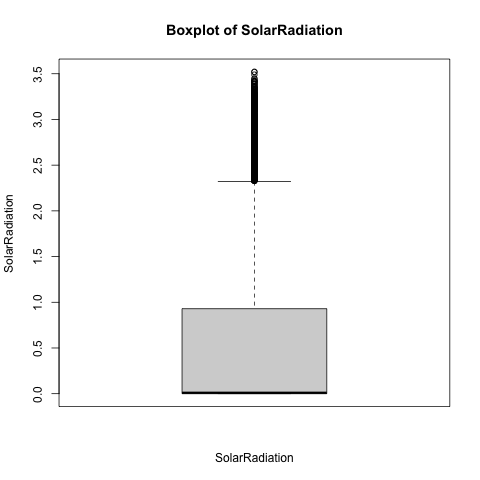

In [ ]:
%%R
boxplot(dfMedidas$Hour, main = "Boxplot of Hour", xlab = "Hour", ylab = "Hour")
boxplot(dfMedidas$Temperature, main = "Boxplot of Temperature", xlab = "Temperature", ylab = "Temperature")
boxplot(dfMedidas$Humidity, main = "Boxplot of Humidity", xlab = "Humidity", ylab = "Humidity")
boxplot(dfMedidas$Visibility, main = "Boxplot of Visibility", xlab = "Visibility", ylab = "Visibility")
boxplot(dfMedidas$Rainfall, main = "Boxplot of Rainfall", xlab = "Rainfall", ylab = "Rainfall")
boxplot(dfMedidas$Snowfall, main = "Boxplot of Snowfall", xlab = "Snowfall", ylab = "Snowfall")
boxplot(dfMedidas$Wind_speed, main = "Boxplot of WindSpeed", xlab = "WindSpeed", ylab = "WindSpeed")
boxplot(dfMedidas$Dew_point_temperature, main = "Boxplot of DewPointTemperature", xlab = "DewPointTemperature", ylab = "DewPointTemperature")
boxplot(dfMedidas$Solar_Radiation, main = "Boxplot of SolarRadiation", xlab = "SolarRadiation", ylab = "SolarRadiation")

Podemos ver que hay una mayor concentración de Outliers en las variables Rainfall, Snowfall y SolarRadiation